# Quickstart: denoise your own signals

This notebook shows the complete use of the library on a small example: provide the noisy signals, choose the two
parameters of the method, train the network, and obtain the denoised signals. It also shows how to measure the
result and how the two parameters are chosen.

TWN2N needs neither a clean reference nor a description of the noise. It needs signals of a system whose response
evolves smoothly in time (a vibrating structure, an impact, a mechanism), sampled several times per period of the
fastest component, and preferably measured in more than one channel.

In [1]:
import os
import sys

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")     # quieter TensorFlow
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")    # these small networks train faster on the CPU
sys.path.insert(0, os.path.abspath(".."))              # use the library from this repository

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import figstyle
import twn2n

figstyle.apply()

## 1. The signals

The library takes an array with one row per time sample and one column per channel. A table read with
`pandas.read_csv` or a list of arrays (several records of the same system) is accepted as well.

Here the signals are synthetic, so that the clean version is known and the result can be checked: four sensors
measure different mixtures of two damped oscillations. To use your own data, replace this cell with the code that
loads your measurements into `noisy`.

In [2]:
fs = 500.0                                   # sampling frequency, Hz
t = np.arange(3000) / fs
modes = np.column_stack([np.exp(-0.8 * t) * np.sin(2 * np.pi * 9 * t),
                         np.exp(-0.5 * t) * np.sin(2 * np.pi * 4 * t)])
mixing = np.array([[1.0, 0.5], [1.0, -0.7], [0.4, 1.0], [-0.8, 0.6]])
clean = modes @ mixing.T                     # shape (3000, 4): four channels

noisy = twn2n.add_noise(clean, kind="white", snr_db=10.0, rng=0)
print("shape of the signals:", noisy.shape)

shape of the signals: (3000, 4)


## 2. Denoising

Two parameters define the method:

* `p` is the number of neighbors taken on each side of every sample. The network predicts the sample at instant
  $t_i$ from the samples at $t_{i-p}, \dots, t_{i-1}$ and $t_{i+1}, \dots, t_{i+p}$ of all channels. The sample at
  $t_i$ itself is hidden from the input.
* `r` is the number of units of the bottleneck of the autoencoder.

The network is created and trained inside `fit_denoise`. The training stops by itself (see the stopping rule in the
README).

In [3]:
model = twn2n.TWN2N(p=2, r=2, seed=0)
denoised = model.fit_denoise(noisy)

print(f"{model.n_parameters_} parameters, {model.epochs_run_} epochs, "
      f"best epoch {model.best_epoch_}, {model.training_time_s_:.0f} s")

8434 parameters, 130 epochs, best epoch 30, 18 s


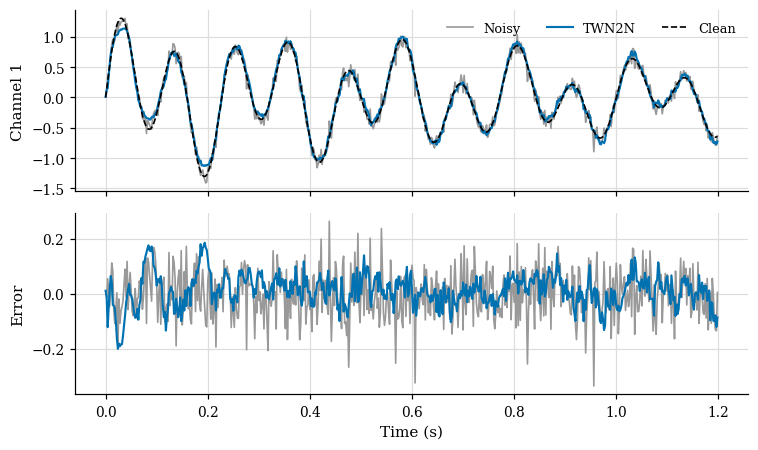

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(7.0, 4.2), sharex=True)
window = slice(0, 600)
figstyle.line(axes[0], t[window], noisy[window, 0], "noisy")
figstyle.line(axes[0], t[window], denoised[window, 0], "twn2n", linewidth=1.4)
figstyle.line(axes[0], t[window], clean[window, 0], "clean")
axes[0].set_ylabel("Channel 1")
axes[0].legend(ncol=3, loc="upper right")
figstyle.line(axes[1], t[window], noisy[window, 0] - clean[window, 0], "noisy")
figstyle.line(axes[1], t[window], denoised[window, 0] - clean[window, 0], "twn2n", linewidth=1.4)
axes[1].set_ylabel("Error")
axes[1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

## 3. Measuring the result

When the clean signal is known, as in a simulation, the signal-to-noise ratio (SNR) is computed directly:

$$\mathrm{SNR} = 20 \log_{10} \frac{\sigma(x_0)}{\sigma(x - x_0)}~,$$

where $x_0$ is the clean signal, $x$ is the signal under evaluation, and $\sigma$ is the standard deviation.

In [5]:
table = pd.DataFrame({
    "input SNR (dB)": twn2n.snr_db(clean, noisy, per_channel=True),
    "output SNR (dB)": twn2n.snr_db(clean, denoised, per_channel=True),
}, index=[f"channel {k + 1}" for k in range(clean.shape[1])])
table["gain (dB)"] = table["output SNR (dB)"] - table["input SNR (dB)"]
print(table.round(2))
print(f"\nall channels pooled: gain of {twn2n.snr_gain_db(clean, noisy, denoised):.2f} dB")

           input SNR (dB)  output SNR (dB)  gain (dB)
channel 1            10.0            16.29       6.29
channel 2            10.0            16.40       6.40
channel 3            10.0            16.28       6.28
channel 4            10.0            16.84       6.84

all channels pooled: gain of 6.23 dB


## 4. Choosing `p` and `r`

The paper fixes both parameters from two arguments and does not tune them, because tuning by the output SNR would
require the clean signal.

* `p = 2` is the smallest symmetric window that contains the central-difference stencil of a second-order system
  once the central sample is masked. It is used in every experiment of the paper.
* `r` is smaller than the number of channels, so that the bottleneck compresses the output. When `r` is not given,
  the library uses two thirds of the number of channels, which gives the values of the paper (4 for six channels
  and 3 for five channels).

## 5. Saving and reusing a trained network

A trained network can denoise other records of the same system, acquired with the same channels and the same
sampling frequency. `save` writes a single `.npz` file.

In [6]:
import tempfile

path = os.path.join(tempfile.mkdtemp(), "quickstart_model.npz")
model.save(path)

loaded = twn2n.TWN2N.load(path)
new_record = twn2n.add_noise(clean, "white", snr_db=10.0, rng=123)        # another noise realization
gain = twn2n.snr_gain_db(clean, new_record, loaded.denoise(new_record))
print(f"gain on a record that was not used for training: {gain:.2f} dB")

gain on a record that was not used for training: 6.34 dB
